In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# NIH EXPERIMENT (PROJECT DIRECTORY SETUP)

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project"
)

NIH_ROOT = (
    PROJECT_ROOT
    / "01_Datasets"
    / "Raw"
    / "NIH"
)

NIH_EXTRACTED = NIH_ROOT / "Extracted"

# Directory verification
assert PROJECT_ROOT.is_dir(), "Project folder not found!"
assert NIH_ROOT.is_dir(), "NIH folder not found!"
assert NIH_EXTRACTED.is_dir(), "Extracted folder not found!"

print("=" * 60)
print("NIH — PROJECT DIRECTORY SETUP")
print("=" * 60)

print("\nProject root:", PROJECT_ROOT)
print("NIH directory:", NIH_ROOT)
print("Extracted dataset:", NIH_EXTRACTED)

NIH — PROJECT DIRECTORY SETUP

Project root: /content/drive/MyDrive/Insight_Hunters_Project
NIH directory: /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/NIH
Extracted dataset: /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/NIH/Extracted


In [ ]:
# NIH PRETRAINING (Verifying the existing splits)

import pandas as pd

metadata_path = NIH_EXTRACTED / "Data_Entry_2017.csv"
train_val_path = NIH_EXTRACTED / "train_val_list.txt"
test_path = NIH_EXTRACTED / "test_list.txt"

nih_df = pd.read_csv(metadata_path)

with open(train_val_path, "r") as f:
    train_val_images = {
        line.strip() for line in f if line.strip()
    }

with open(test_path, "r") as f:
    test_images = {
        line.strip() for line in f if line.strip()
    }

metadata_images = set(nih_df["Image Index"])

print("=" * 65)
print("NIH (EXISTING SPLIT VERIFICATION)")
print("=" * 65)

print("\nTotal metadata records:", len(nih_df))
print("Train/validation images:", len(train_val_images))
print("Test images:", len(test_images))

print("\nImage overlap:",
      len(train_val_images & test_images))

print("Images missing from metadata:",
      len((train_val_images | test_images) - metadata_images))

print("Metadata images missing from both lists:",
      len(metadata_images - (train_val_images | test_images)))

train_val_patients = set(
    nih_df.loc[
        nih_df["Image Index"].isin(train_val_images),
        "Patient ID"
    ]
)

test_patients = set(
    nih_df.loc[
        nih_df["Image Index"].isin(test_images),
        "Patient ID"
    ]
)

print("\nTrain/validation patients:", len(train_val_patients))
print("Test patients:", len(test_patients))

print("Patient overlap:",
      len(train_val_patients & test_patients))

print("\nSTEP 1 VERIFICATION COMPLETE")

NIH (EXISTING SPLIT VERIFICATION)

Total metadata records: 112120
Train/validation images: 86524
Test images: 25596

Image overlap: 0
Images missing from metadata: 0
Metadata images missing from both lists: 0

Train/validation patients: 28008
Test patients: 2797
Patient overlap: 0

STEP 1 VERIFICATION COMPLETE


In [ ]:
# NIH PRETRAINING (PATIENT-LEVEL TRAIN/VAL SPLIT)

import numpy as np
from sklearn.model_selection import GroupShuffleSplit

# Selecting images found only in the NIH training/validation partition
nih_trainval_df = nih_df[
    nih_df["Image Index"].isin(train_val_images)
].copy()

# Splitting by patient to prevent patient leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        nih_trainval_df,
        groups=nih_trainval_df["Patient ID"]
    )
)

nih_train_df = nih_trainval_df.iloc[train_idx].copy()
nih_val_df = nih_trainval_df.iloc[val_idx].copy()

# Verifying the patient separation
train_patients = set(nih_train_df["Patient ID"])
val_patients = set(nih_val_df["Patient ID"])

assert len(train_patients & val_patients) == 0

# Verifying the image separation
train_images = set(nih_train_df["Image Index"])
val_images = set(nih_val_df["Image Index"])

assert len(train_images & val_images) == 0

# Verifying that the NIH test partition remains excluded
assert len(train_images & test_images) == 0
assert len(val_images & test_images) == 0

print("=" * 65)
print("NIH (PATIENT-LEVEL TRAIN/VALIDATION SPLIT)")
print("=" * 65)

print("\nTraining images:", len(nih_train_df))
print("Validation images:", len(nih_val_df))

print("\nTraining patients:", len(train_patients))
print("Validation patients:", len(val_patients))

print("\nPatient overlap:", len(train_patients & val_patients))
print("Image overlap:", len(train_images & val_images))

print("\nNIH test images remain untouched:", len(test_images))


NIH (PATIENT-LEVEL TRAIN/VALIDATION SPLIT)

Training images: 73916
Validation images: 12608

Training patients: 23806
Validation patients: 4202

Patient overlap: 0
Image overlap: 0

NIH test images remain untouched: 25596


In [ ]:
# NIH PRETRAINING (LABEL DISTRIBUTION VERIFICATION)

import pandas as pd

# Extracting the finding labels from each partition
train_labels = nih_train_df["Finding Labels"].str.split("|")
val_labels = nih_val_df["Finding Labels"].str.split("|")

# Counting each finding
train_counts = train_labels.explode().value_counts()
val_counts = val_labels.explode().value_counts()

# Combining the counts into a comparison table
label_comparison = pd.DataFrame({
    "Training Count": train_counts,
    "Validation Count": val_counts
}).fillna(0).astype(int)

# Calculating the prevalence within each partition
label_comparison["Training %"] = (
    label_comparison["Training Count"]
    / len(nih_train_df) * 100
).round(2)

label_comparison["Validation %"] = (
    label_comparison["Validation Count"]
    / len(nih_val_df) * 100
).round(2)

label_comparison["Difference (pp)"] = (
    label_comparison["Validation %"]
    - label_comparison["Training %"]
).round(2)

label_comparison = label_comparison.sort_index()

print("=" * 70)
print("NIH (TRAINING VS VALIDATION LABEL DISTRIBUTION)")
print("=" * 70)

display(label_comparison)

print("\nTraining images:", len(nih_train_df))
print("Validation images:", len(nih_val_df))

print("\nLabels missing from training:",
      label_comparison.index[
          label_comparison["Training Count"] == 0
      ].tolist())

print("Labels missing from validation:",
      label_comparison.index[
          label_comparison["Validation Count"] == 0
      ].tolist())

NIH (TRAINING VS VALIDATION LABEL DISTRIBUTION)


,Training Count,Validation Count,Training %,Validation %,Difference (pp)
Finding Labels,,,,,
Atelectasis,7003,1277,9.47,10.13,0.66
Cardiomegaly,1453,254,1.97,2.01,0.04
Consolidation,2482,370,3.36,2.93,-0.43
Edema,1201,177,1.62,1.40,-0.22
Effusion,7415,1244,10.03,9.87,-0.16
Emphysema,1274,149,1.72,1.18,-0.54
Fibrosis,1051,200,1.42,1.59,0.17
Hernia,113,28,0.15,0.22,0.07
Infiltration,11853,1929,16.04,15.30,-0.74



Training images: 73916
Validation images: 12608

Labels missing from training: []
Labels missing from validation: []


In [ ]:
# NIH PRETRAINING (MULTI-LABEL TARGET PREPARATION)

import numpy as np

NIH_CLASSES = [
    "Atelectasis",
    "Cardiomegaly",
    "Consolidation",
    "Edema",
    "Effusion",
    "Emphysema",
    "Fibrosis",
    "Hernia",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pleural_Thickening",
    "Pneumonia",
    "Pneumothorax"
]

def encode_nih_labels(dataframe):
    """Convert NIH finding labels into 14 binary targets."""

    encoded = np.zeros(
        (len(dataframe), len(NIH_CLASSES)),
        dtype=np.float32
    )

    class_to_index = {
        label: index
        for index, label in enumerate(NIH_CLASSES)
    }

    for row_index, label_string in enumerate(
        dataframe["Finding Labels"]
    ):
        labels = label_string.split("|")

        for label in labels:
            if label in class_to_index:
                encoded[
                    row_index,
                    class_to_index[label]
                ] = 1.0

    return encoded


# Encoding the training and validation labels
nih_y_train = encode_nih_labels(nih_train_df)
nih_y_val = encode_nih_labels(nih_val_df)

print("=" * 65)
print("NIH (MULTI-LABEL TARGET PREPARATION)")
print("=" * 65)

print("\nNumber of disease classes:", len(NIH_CLASSES))
print("Training target shape:", nih_y_train.shape)
print("Validation target shape:", nih_y_val.shape)

print("\nTraining positive labels per class:")
for label, count in zip(
    NIH_CLASSES,
    nih_y_train.sum(axis=0).astype(int)
):
    print(f"{label:20s}: {count}")

# Verifying the binary encoding
assert np.isin(nih_y_train, [0, 1]).all()
assert np.isin(nih_y_val, [0, 1]).all()

NIH (MULTI-LABEL TARGET PREPARATION)

Number of disease classes: 14
Training target shape: (73916, 14)
Validation target shape: (12608, 14)

Training positive labels per class:
Atelectasis         : 7003
Cardiomegaly        : 1453
Consolidation       : 2482
Edema               : 1201
Effusion            : 7415
Emphysema           : 1274
Fibrosis            : 1051
Hernia              : 113
Infiltration        : 11853
Mass                : 3452
Nodule              : 4042
Pleural_Thickening  : 1870
Pneumonia           : 742
Pneumothorax        : 2287


In [ ]:
# NIH PRETRAINING (VERIFYING THE IMAGE PATH STRUCTURE)

from pathlib import Path

print("=" * 65)
print("NIH (IMAGE PATH VERIFICATION)")
print("=" * 65)

# Inspecting the first numbered image folder
sample_folder = NIH_EXTRACTED / "images_001"

print("\nInspecting:", sample_folder)

if not sample_folder.exists():
    print("ERROR: images_001 folder not found.")

else:
    print("\nImmediate contents:")

    for item in sorted(sample_folder.iterdir())[:10]:
        print(
            "FOLDER:" if item.is_dir() else "FILE:",
            item.name
        )

    # Finding a few PNG images
    sample_images = []

    for image_path in sample_folder.rglob("*.png"):
        sample_images.append(image_path)

        if len(sample_images) == 3:
            break

    print("\nSample image paths:")

    for path in sample_images:
        print(path)

    print("\nSample images found:", len(sample_images))

NIH (IMAGE PATH VERIFICATION)

Inspecting: /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/NIH/Extracted/images_001

Immediate contents:
FOLDER: images

Sample image paths:
/content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/NIH/Extracted/images_001/images/00001088_022.png
/content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/NIH/Extracted/images_001/images/00001088_023.png
/content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/NIH/Extracted/images_001/images/00001088_024.png

Sample images found: 3


In [ ]:
# NIH PRETRAINING (BUILDING IMAGE-PATH INDEX)

from pathlib import Path

print("=" * 65)
print("NIH (IMAGE-PATH INDEX VERIFICATION)")
print("=" * 65)

# Mapping each image filename to its existing location
nih_image_map = {}

duplicate_names = []

for folder in sorted(NIH_EXTRACTED.glob("images_*")):

    image_dir = folder / "images"

    if not image_dir.is_dir():
        continue

    for image_path in image_dir.glob("*.png"):

        if image_path.name in nih_image_map:
            duplicate_names.append(image_path.name)
        else:
            nih_image_map[image_path.name] = str(image_path)

print("\nIndexed images:", len(nih_image_map))
print("Duplicate filenames:", len(duplicate_names))

# Matching the filenames to the metadata
train_filenames = nih_train_df["Image Index"].tolist()
val_filenames = nih_val_df["Image Index"].tolist()

missing_train = [
    name for name in train_filenames
    if name not in nih_image_map
]

missing_val = [
    name for name in val_filenames
    if name not in nih_image_map
]

print("\nMissing training image paths:", len(missing_train))
print("Missing validation image paths:", len(missing_val))

# Creating ordered path lists corresponding to the target arrays
if duplicate_names or missing_train or missing_val:
    print("\n Image-path verification failed.")
    print("Do not proceed to training yet.")
else:
    nih_train_paths = [
        nih_image_map[name]
        for name in train_filenames
    ]

    nih_val_paths = [
        nih_image_map[name]
        for name in val_filenames
    ]

    assert len(nih_train_paths) == len(nih_y_train)
    assert len(nih_val_paths) == len(nih_y_val)

    print("\nTraining paths:", len(nih_train_paths))
    print("Validation paths:", len(nih_val_paths))

    print("\nSample training path:")
    print(nih_train_paths[0])


NIH (IMAGE-PATH INDEX VERIFICATION)

Indexed images: 112120
Duplicate filenames: 0

Missing training image paths: 0
Missing validation image paths: 0

Training paths: 73916
Validation paths: 12608

Sample training path:
/content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/NIH/Extracted/images_001/images/00000001_000.png


In [ ]:
# NIH PRETRAINING (IMAGE-LOADING PIPELINE)

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

def load_nih_image(path, labels):
    # Reading images
    image_bytes = tf.io.read_file(path)

    # Decoding PNG as three-channel RGB
    image = tf.image.decode_png(
        image_bytes,
        channels=3
    )

    # Resizing images
    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    # Converting to float32
    image = tf.cast(image, tf.float32)

    # Keeping the pixel values in the 0–255 range.
    # ResNet50 preprocessing will be applied
    # inside the model, not here.

    return image, labels


def build_nih_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_nih_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


nih_train_ds = build_nih_dataset(
    nih_train_paths,
    nih_y_train,
    training=True
)

nih_val_ds = build_nih_dataset(
    nih_val_paths,
    nih_y_val,
    training=False
)

# Testing one batch
sample_images, sample_labels = next(
    iter(nih_train_ds)
)

print("=" * 65)
print("NIH (IMAGE PIPELINE VERIFICATION)")
print("=" * 65)

print("\nImage batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)

print("\nImage dtype:", sample_images.dtype)
print("Label dtype:", sample_labels.dtype)

print("\nPixel minimum:", tf.reduce_min(sample_images).numpy())
print("Pixel maximum:", tf.reduce_max(sample_images).numpy())

print("\nLabels for first image:")
print(sample_labels[0].numpy())

assert sample_images.shape == (32, 224, 224, 3)
assert sample_labels.shape == (32, 14)

assert tf.reduce_all(
    tf.math.is_finite(sample_images)
).numpy()


NIH (IMAGE PIPELINE VERIFICATION)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 14)

Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'float32'>

Pixel minimum: 0.0
Pixel maximum: 255.0

Labels for first image:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [ ]:
# NIH PRETRAINING (BUILDING THE RESNET50 MODEL)

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50

tf.keras.utils.set_random_seed(42)

# Input
inputs = layers.Input(
    shape=(224, 224, 3),
    name="nih_input"
)

# ResNet50 preprocessing inside the model
x = layers.Lambda(
    tf.keras.applications.resnet50.preprocess_input,
    name="resnet50_preprocessing"
)(inputs)

# ImageNet-pretrained backbone
nih_backbone = ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freezing the backbone for the initial training
nih_backbone.trainable = False

# Extracting image features
x = nih_backbone(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu",
    name="nih_dense"
)(x)

outputs = layers.Dense(
    14,
    activation="sigmoid",
    name="nih_predictions"
)(x)

nih_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="NIH_ResNet50"
)

# Compiling for multi-label classification
nih_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="binary_accuracy"
        ),
        tf.keras.metrics.AUC(
            name="auc",
            multi_label=True,
            num_labels=14
        )
    ]
)

print("=" * 65)
print("NIH (RESNET50 MODEL CONFIGURATION)")
print("=" * 65)

print("\nModel input:", nih_model.input_shape)
print("Model output:", nih_model.output_shape)

print("\nTotal parameters:", nih_model.count_params())

print("\nTrainable parameters:",
      sum(
          tf.keras.backend.count_params(w)
          for w in nih_model.trainable_weights
      ))

print("\nBackbone frozen:", not nih_backbone.trainable)

assert nih_model.input_shape == (None, 224, 224, 3)
assert nih_model.output_shape == (None, 14)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
NIH (RESNET50 MODEL CONFIGURATION)

Model input: (None, 224, 224, 3)
Model output: (None, 14)

Total parameters: 23851790

Trainable parameters: 264078

Backbone frozen: True


In [ ]:
# NIH PRETRAINING (CHECKPOINTS AND CALLBACKS)

from pathlib import Path
import tensorflow as tf

# Separating the directory for the NIH experiment
NIH_CHECKPOINT_DIR = (
    PROJECT_ROOT
    / "03_Model_Checkpoints"
    / "ResNet50_NIH_Pretraining"
)

NIH_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Stage 1 checkpoint
NIH_STAGE1_PATH = (
    NIH_CHECKPOINT_DIR
    / "nih_resnet50_stage1_best.keras"
)

# Stage 2 checkpoint
NIH_STAGE2_PATH = (
    NIH_CHECKPOINT_DIR
    / "nih_resnet50_stage2_best.keras"
)

def create_nih_callbacks(checkpoint_path):

    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),

        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-7,
            verbose=1
        )
    ]

print("=" * 65)
print("NIH (CHECKPOINT CONFIGURATION)")
print("=" * 65)

print("\nCheckpoint directory:", NIH_CHECKPOINT_DIR)
print("\nStage 1 checkpoint:", NIH_STAGE1_PATH)
print("Stage 2 checkpoint:", NIH_STAGE2_PATH)

print("\nStage 1 checkpoint exists:", NIH_STAGE1_PATH.exists())
print("Stage 2 checkpoint exists:", NIH_STAGE2_PATH.exists())


NIH (CHECKPOINT CONFIGURATION)

Checkpoint directory: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining

Stage 1 checkpoint: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage1_best.keras
Stage 2 checkpoint: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage2_best.keras

Stage 1 checkpoint exists: False
Stage 2 checkpoint exists: False


In [ ]:
# NIH PRETRAINING (GPU VERIFICATION)

import tensorflow as tf
import subprocess

print("=" * 65)
print("NIH (GPU AND RUNTIME VERIFICATION)")
print("=" * 65)

print("\nTensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("\nGPUs detected:", len(gpus))

for gpu in gpus:
    print("GPU:", gpu.name)

print("\nNVIDIA GPU INFORMATION:\n")

result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=name,memory.total,memory.free",
        "--format=csv,noheader"
    ],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print(result.stdout)
else:
    print("NVIDIA GPU information unavailable.")

print(
    "\nPrecision policy:",
    tf.keras.mixed_precision.global_policy().name
)


NIH (GPU AND RUNTIME VERIFICATION)

TensorFlow version: 2.21.0

GPUs detected: 1
GPU: /physical_device:GPU:0

NVIDIA GPU INFORMATION:

Tesla T4, 15360 MiB, 14544 MiB


Precision policy: float32


In [ ]:
# NIH PRETRAINING (TRAINING PERFORMANCE TEST)

import tensorflow as tf
import time

print("=" * 65)
print("NIH (TRAINING PERFORMANCE TEST)")
print("=" * 65)

# Creating a separate benchmark model
benchmark_inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

# Applying ResNet50 preprocessing
benchmark_x = tf.keras.layers.Lambda(
    tf.keras.applications.resnet50.preprocess_input
)(benchmark_inputs)

# Independent ResNet50 backbone
benchmark_backbone = tf.keras.applications.ResNet50(
    include_top=False,
    weights=None,
    input_shape=(224, 224, 3)
)

benchmark_backbone.trainable = False

benchmark_x = benchmark_backbone(
    benchmark_x,
    training=False
)

benchmark_x = tf.keras.layers.GlobalAveragePooling2D()(
    benchmark_x
)

benchmark_x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(benchmark_x)

benchmark_outputs = tf.keras.layers.Dense(
    14,
    activation="sigmoid"
)(benchmark_x)

benchmark_model = tf.keras.Model(
    benchmark_inputs,
    benchmark_outputs
)

# Compiling the benchmark model
benchmark_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="binary_crossentropy"
)

# Using only 10 batches
benchmark_ds = nih_train_ds.take(10)

print("\nBenchmark batches: 10")
print("Batch size:", BATCH_SIZE)

# Warming up the GPU
warmup_images, warmup_labels = next(iter(benchmark_ds))

benchmark_model.train_on_batch(
    warmup_images,
    warmup_labels
)

# Measuring the training time
start_time = time.perf_counter()

benchmark_model.fit(
    benchmark_ds,
    epochs=1,
    verbose=1
)

elapsed_seconds = time.perf_counter() - start_time

seconds_per_batch = elapsed_seconds / 10

estimated_epoch_minutes = (
    seconds_per_batch
    * len(nih_train_ds)
    / 60
)

print("\n" + "=" * 65)
print("BENCHMARK RESULTS")
print("=" * 65)

print(f"\nTotal benchmark time: {elapsed_seconds:.2f} seconds")
print(f"Average time per batch: {seconds_per_batch:.2f} seconds")
print(
    f"Estimated full training epoch: "
    f"{estimated_epoch_minutes:.2f} minutes"
)


NIH (TRAINING PERFORMANCE TEST)

Benchmark batches: 10
Batch size: 32
10/10 ━━━━━━━━━━━━━━━━━━━━ 123s 12s/step - loss: 0.4159

BENCHMARK RESULTS

Total benchmark time: 122.76 seconds
Average time per batch: 12.28 seconds
Estimated full training epoch: 472.64 minutes


In [ ]:
# NIH (IMAGE-LOADING PERFORMANCE TEST)

import time

print("=" * 65)
print("NIH (IMAGE LOADING PERFORMANCE TEST)")
print("=" * 65)

start_time = time.perf_counter()

batch_count = 0

for images, labels in nih_train_ds.take(10):
    # Forcing TensorFlow to finish loading the batch
    _ = images.numpy()
    batch_count += 1

elapsed = time.perf_counter() - start_time

print(f"\nBatches loaded: {batch_count}")
print(f"Images loaded: {batch_count * 32}")
print(f"Total loading time: {elapsed:.2f} seconds")
print(f"Average loading time per batch: {elapsed / batch_count:.2f} seconds")


NIH (IMAGE LOADING PERFORMANCE TEST)

Batches loaded: 10
Images loaded: 320
Total loading time: 120.39 seconds
Average loading time per batch: 12.04 seconds


In [ ]:
# NIH (CHECKING THE LOCAL STORAGE)

import shutil

total, used, free = shutil.disk_usage("/content")

gb = 1024 ** 3

print("=" * 60)
print("COLAB LOCAL STORAGE")
print("=" * 60)

print(f"\nTotal storage: {total / gb:.2f} GB")
print(f"Used storage:  {used / gb:.2f} GB")
print(f"Free storage:  {free / gb:.2f} GB")

print("\nNIH dataset: 112,120 chest X-ray images")
print("Training images: 73,916")
print("Validation images: 12,608")


COLAB LOCAL STORAGE

Total storage: 112.64 GB
Used storage:  42.89 GB
Free storage:  69.73 GB

NIH dataset: 112,120 chest X-ray images
Training images: 73,916
Validation images: 12,608


In [ ]:
# NIH (CHECKING THE TRAINING DATASET SIZE)

import os
import shutil

print("=" * 65)
print("NIH (TRAINING DATASET SIZE CHECK)")
print("=" * 65)

# Combining the training and validation image paths
required_paths = set(nih_train_paths) | set(nih_val_paths)

total_bytes = 0
missing_files = 0

for path in required_paths:
    try:
        total_bytes += os.path.getsize(str(path))
    except OSError:
        missing_files += 1

gb = 1024 ** 3

free_bytes = shutil.disk_usage("/content").free

print(f"\nRequired images: {len(required_paths):,}")
print(f"Missing/unreadable paths: {missing_files:,}")

print(f"\nDataset size: {total_bytes / gb:.2f} GB")
print(f"Available local storage: {free_bytes / gb:.2f} GB")

# Keeping some free space for runtime operations
safety_margin = 10 * gb

if missing_files:
    print("\n Some image paths could not be measured.")
elif total_bytes + safety_margin <= free_bytes:
    print("\n Dataset appears to fit on local storage.")
    print("A 10 GB safety margin would remain.")
else:
    print("\n Dataset may be too large for safe local copying.")


NIH (TRAINING DATASET SIZE CHECK)

Required images: 86,524
Missing/unreadable paths: 0

Dataset size: 32.45 GB
Available local storage: 69.73 GB

 Dataset appears to fit on local storage.
A 10 GB safety margin would remain.


In [ ]:
# NIH (COPY IMAGES TO COLAB LOCAL STORAGE)

from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm
import shutil
import os
import time

print("=" * 65)
print("NIH (LOCAL IMAGE STAGING)")
print("=" * 65)

LOCAL_NIH_DIR = Path("/content/nih_local_images")
LOCAL_NIH_DIR.mkdir(parents=True, exist_ok=True)

# Collect unique training and validation images
required_paths = sorted(
    set(map(str, nih_train_paths)) |
    set(map(str, nih_val_paths))
)

print(f"\nImages to stage: {len(required_paths):,}")
print(f"Destination: {LOCAL_NIH_DIR}")
print("\nOriginal Google Drive images will remain unchanged.")

# Preserving each image's unique filename.
# NIH filenames are unique across the indexed dataset.
def copy_nih_image(source_path):
    source = Path(source_path)
    destination = LOCAL_NIH_DIR / source.name

    if destination.exists():
        if destination.stat().st_size == source.stat().st_size:
            return "skipped"

    shutil.copy2(source, destination)

    return "copied"

start_time = time.perf_counter()

copied = 0
skipped = 0
failed = []

# Moderate concurrency to avoid overwhelming Google Drive
with ThreadPoolExecutor(max_workers=8) as executor:
    futures = {
        executor.submit(copy_nih_image, path): path
        for path in required_paths
    }

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Copying NIH images"
    ):
        try:
            result = future.result()

            if result == "copied":
                copied += 1
            else:
                skipped += 1

        except Exception as error:
            failed.append((futures[future], str(error)))

elapsed = time.perf_counter() - start_time

print("\n" + "=" * 65)
print("LOCAL STAGING RESULTS")
print("=" * 65)

print(f"\nCopied: {copied:,}")
print(f"Already present: {skipped:,}")
print(f"Failed: {len(failed):,}")
print(f"Time elapsed: {elapsed / 60:.2f} minutes")

if failed:
    print("\nFirst few failures:")
    for path, error in failed[:5]:
        print(path, "->", error)
else:
    print("\n ALL REQUIRED NIH IMAGES STAGED SUCCESSFULLY")

NIH (LOCAL IMAGE STAGING)

Images to stage: 86,524
Destination: /content/nih_local_images

Original Google Drive images will remain unchanged.


Copying NIH images:   0%|          | 0/86524 [00:00<?, ?it/s]


LOCAL STAGING RESULTS

Copied: 86,524
Already present: 0
Failed: 0
Time elapsed: 132.90 minutes

 ALL REQUIRED NIH IMAGES STAGED SUCCESSFULLY


In [ ]:
import os
import tensorflow as tf

print("=" * 65)
print("NIH LOCAL DATASET PREPARATION")
print("=" * 65)

LOCAL_DIR = "/content/nih_local_images"

# Replacing Google Drive paths with local paths
nih_train_local_paths = [
    os.path.join(LOCAL_DIR, os.path.basename(path))
    for path in nih_train_paths
]

nih_val_local_paths = [
    os.path.join(LOCAL_DIR, os.path.basename(path))
    for path in nih_val_paths
]

# Verifying that every required image exists locally
missing_train = sum(
    not os.path.isfile(path)
    for path in nih_train_local_paths
)

missing_val = sum(
    not os.path.isfile(path)
    for path in nih_val_local_paths
)

print(f"Training images: {len(nih_train_local_paths):,}")
print(f"Validation images: {len(nih_val_local_paths):,}")
print(f"Missing training images: {missing_train}")
print(f"Missing validation images: {missing_val}")

assert missing_train == 0, "Some training images are missing!"
assert missing_val == 0, "Some validation images are missing!"

print("\nAll NIH images verified in local storage!")

NIH LOCAL DATASET PREPARATION
Training images: 73,916
Validation images: 12,608
Missing training images: 0
Missing validation images: 0

All NIH images verified in local storage!


In [ ]:
# Rebuilding the datasets using local image paths

nih_train_local_ds = tf.data.Dataset.from_tensor_slices(
    (nih_train_local_paths, nih_y_train)
)

nih_train_local_ds = (
    nih_train_local_ds
    .shuffle(buffer_size=2048, seed=42)
    .map(load_nih_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

nih_val_local_ds = tf.data.Dataset.from_tensor_slices(
    (nih_val_local_paths, nih_y_val)
)

nih_val_local_ds = (
    nih_val_local_ds
    .map(load_nih_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

print("=" * 65)
print("NIH LOCAL TENSORFLOW DATASETS")
print("=" * 65)

print(f"Training batches: {len(nih_train_local_ds):,}")
print(f"Validation batches: {len(nih_val_local_ds):,}")

print("\nLocal TensorFlow datasets created successfully!")

NIH LOCAL TENSORFLOW DATASETS
Training batches: 2,310
Validation batches: 394

Local TensorFlow datasets created successfully!


In [ ]:
import time

print("=" * 65)
print("NIH LOCAL IMAGE LOADING BENCHMARK")
print("=" * 65)

num_batches = 10

start_time = time.perf_counter()

for images, labels in nih_train_local_ds.take(num_batches):
    # Forcing TensorFlow to finish loading each batch
    _ = images.numpy()
    _ = labels.numpy()

elapsed = time.perf_counter() - start_time

seconds_per_batch = elapsed / num_batches
estimated_epoch_minutes = (
    seconds_per_batch * len(nih_train_local_ds)
) / 60

print(f"\nBatches tested: {num_batches}")
print(f"Total loading time: {elapsed:.2f} seconds")
print(f"Average per batch: {seconds_per_batch:.2f} seconds")
print(f"Estimated full epoch loading time: {estimated_epoch_minutes:.2f} minutes")

print("\nPrevious Google Drive loading benchmarks:")
print("Run 1: 63.78 seconds / 10 batches")
print("Run 2: 120.39 seconds / 10 batches")

NIH LOCAL IMAGE LOADING BENCHMARK

Batches tested: 10
Total loading time: 3.85 seconds
Average per batch: 0.39 seconds
Estimated full epoch loading time: 14.84 minutes

Previous Google Drive loading benchmarks:
Run 1: 63.78 seconds / 10 batches
Run 2: 120.39 seconds / 10 batches


In [ ]:
import time

print("=" * 65)
print("NIH LOCAL TRAINING SPEED BENCHMARK")
print("=" * 65)

# Using only 10 batches from local storage
local_benchmark_ds = nih_train_local_ds.take(10)

# Warming up TensorFlow and GPU
benchmark_model.train_on_batch(
    *next(iter(local_benchmark_ds))
)

start_time = time.perf_counter()

history = benchmark_model.fit(
    local_benchmark_ds,
    epochs=1,
    verbose=1
)

elapsed = time.perf_counter() - start_time

seconds_per_batch = elapsed / 10
estimated_epoch_minutes = (
    seconds_per_batch * len(nih_train_local_ds)
) / 60

print("\n" + "=" * 65)
print("LOCAL TRAINING BENCHMARK RESULTS")
print("=" * 65)

print(f"10 batches: {elapsed:.2f} seconds")
print(f"Average per batch: {seconds_per_batch:.2f} seconds")
print(f"Estimated full training epoch: {estimated_epoch_minutes:.2f} minutes")

print("\nPrevious Google Drive training benchmarks:")
print("Run 1: 263.79 minutes per epoch")
print("Run 2: 472.64 minutes per epoch")

NIH LOCAL TRAINING SPEED BENCHMARK
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 354ms/step - loss: 0.2097

LOCAL TRAINING BENCHMARK RESULTS
10 batches: 3.74 seconds
Average per batch: 0.37 seconds
Estimated full training epoch: 14.41 minutes

Previous Google Drive training benchmarks:
Run 1: 263.79 minutes per epoch
Run 2: 472.64 minutes per epoch


In [ ]:
from pathlib import Path

local_dir = Path("/content/nih_local_images")

if local_dir.exists():
    count = len(list(local_dir.glob("*.png")))
    print(f"Local NIH images: {count:,}")
else:
    print("Local NIH images are no longer available.")

Local NIH images are no longer available.


In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content/drive/MyDrive")

print(f"Total storage: {total / (1024**3):.2f} GB")
print(f"Used storage: {used / (1024**3):.2f} GB")
print(f"Available storage: {free / (1024**3):.2f} GB")

Total storage: 225.83 GB
Used storage: 30.78 GB
Available storage: 195.06 GB


In [ ]:
from pathlib import Path

TFRECORD_DIR = (
    Path("/content/drive/MyDrive/Insight_Hunters_Project")
    / "01_Datasets"
    / "Processed"
    / "NIH_TFRecords"
)

TFRECORD_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("NIH TFRECORD STORAGE")
print("=" * 60)
print(f"Directory: {TFRECORD_DIR}")
print(f"Exists: {TFRECORD_DIR.is_dir()}")

NIH TFRECORD STORAGE
Directory: /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Processed/NIH_TFRecords
Exists: True


In [ ]:
import tensorflow as tf
import numpy as np
from pathlib import Path

TFRECORD_DIR = (
    Path("/content/drive/MyDrive/Insight_Hunters_Project")
    / "01_Datasets"
    / "Processed"
    / "NIH_TFRecords"
)

TFRECORD_DIR.mkdir(parents=True, exist_ok=True)

test_file = TFRECORD_DIR / "nih_test_10_images.tfrecord"

def bytes_feature(value):
    return tf.train.Feature(
        bytes_list=tf.train.BytesList(value=[value])
    )

def float_feature(values):
    return tf.train.Feature(
        float_list=tf.train.FloatList(value=values)
    )

with tf.io.TFRecordWriter(str(test_file)) as writer:

    for i in range(10):

        image_path = str(nih_train_paths[i])

        # Reading the original PNG bytes without changing the image quality
        image_bytes = tf.io.read_file(image_path).numpy()

        labels = np.asarray(
            nih_y_train[i], dtype=np.float32
        ).tolist()

        example = tf.train.Example(
            features=tf.train.Features(
                feature={
                    "image": bytes_feature(image_bytes),
                    "labels": float_feature(labels)
                }
            )
        )

        writer.write(example.SerializeToString())

print("=" * 60)
print("NIH TFRECORD TEST")
print("=" * 60)

print(f"File created: {test_file}")
print(f"File size: {test_file.stat().st_size / 1024**2:.2f} MB")
print("Images stored: 10")
print("Labels per image: 14")

NIH TFRECORD TEST
File created: /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Processed/NIH_TFRecords/nih_test_10_images.tfrecord
File size: 3.96 MB
Images stored: 10
Labels per image: 14


In [ ]:
import numpy as np
import tensorflow as tf

print("=" * 60)
print("NIH TFRECORD INTEGRITY CHECK")
print("=" * 60)

feature_description = {
    "image": tf.io.FixedLenFeature([], tf.string),
    "labels": tf.io.FixedLenFeature([14], tf.float32)
}

dataset = tf.data.TFRecordDataset(str(test_file))

verified = 0

for i, record in enumerate(dataset):

    example = tf.io.parse_single_example(
        record,
        feature_description
    )

    # Recovering the original image bytes
    recovered_image = example["image"].numpy()

    # Recovering the 14 disease labels
    recovered_labels = example["labels"].numpy()

    # Comparing against the original image
    with open(str(nih_train_paths[i]), "rb") as f:
        original_image = f.read()

    assert recovered_image == original_image, (
        f"Image mismatch at index {i}"
    )

    # Comparing against the original labels
    np.testing.assert_array_equal(
        recovered_labels,
        np.asarray(nih_y_train[i], dtype=np.float32)
    )

    # Verifying the stored image can be decoded
    decoded_image = tf.io.decode_png(
        recovered_image,
        channels=3
    )

    assert decoded_image.shape[-1] == 3

    verified += 1

print(f"Records verified: {verified}")

assert verified == 10, (
    f"Expected 10 records, found {verified}"
)

print("Image bytes: MATCH")
print("Disease labels: MATCH")
print("Image decoding: SUCCESSFUL")

print("\nALL TFRECORD INTEGRITY CHECKS PASSED!")

NIH TFRECORD INTEGRITY CHECK
Records verified: 10
Image bytes: MATCH
Disease labels: MATCH
Image decoding: SUCCESSFUL

ALL TFRECORD INTEGRITY CHECKS PASSED!


In [ ]:
import os
import math
import numpy as np
import tensorflow as tf
from pathlib import Path
from tqdm.auto import tqdm

SHARD_SIZE = 1000

TRAIN_TFRECORD_DIR = TFRECORD_DIR / "train"
VAL_TFRECORD_DIR = TFRECORD_DIR / "val"

TRAIN_TFRECORD_DIR.mkdir(parents=True, exist_ok=True)
VAL_TFRECORD_DIR.mkdir(parents=True, exist_ok=True)


def create_tfrecord_shards(paths, labels, output_dir, split_name):

    assert len(paths) == len(labels), "Image/label count mismatch!"

    total_images = len(paths)
    total_shards = math.ceil(total_images / SHARD_SIZE)

    print(f"\nPreparing {split_name.upper()} TFRecords")
    print(f"Images: {total_images:,}")
    print(f"Shards: {total_shards}")
    print(f"Images per shard: {SHARD_SIZE:,}")

    for shard_idx in tqdm(range(total_shards), desc=split_name):

        start = shard_idx * SHARD_SIZE
        end = min(start + SHARD_SIZE, total_images)

        output_file = (
            output_dir /
            f"{split_name}_{shard_idx:03d}.tfrecord"
        )

        temp_file = output_file.with_suffix(".tmp")

        # Skipping the shards already completed
        if output_file.exists():
            continue

        try:
            with tf.io.TFRecordWriter(str(temp_file)) as writer:

                for i in range(start, end):

                    image_bytes = tf.io.read_file(
                        str(paths[i])
                    ).numpy()

                    image_labels = np.asarray(
                        labels[i],
                        dtype=np.float32
                    ).tolist()

                    example = tf.train.Example(
                        features=tf.train.Features(
                            feature={
                                "image": bytes_feature(image_bytes),
                                "labels": float_feature(image_labels)
                            }
                        )
                    )

                    writer.write(example.SerializeToString())

            # Mark shard complete only after writing finishes
            os.replace(temp_file, output_file)

        except Exception:
            if temp_file.exists():
                temp_file.unlink()
            raise

    print(f"\n{split_name.upper()} shards completed!")


print("=" * 65)
print("NIH TFRECORD SHARD PREPARATION")
print("=" * 65)

create_tfrecord_shards(
    nih_train_paths,
    nih_y_train,
    TRAIN_TFRECORD_DIR,
    "train"
)

create_tfrecord_shards(
    nih_val_paths,
    nih_y_val,
    VAL_TFRECORD_DIR,
    "val"
)

print("\nALL NIH TFRECORD SHARDS CREATED!")

NIH TFRECORD SHARD PREPARATION

Preparing TRAIN TFRecords
Images: 73,916
Shards: 74
Images per shard: 1,000


train:   0%|          | 0/74 [00:00<?, ?it/s]


TRAIN shards completed!

Preparing VAL TFRecords
Images: 12,608
Shards: 13
Images per shard: 1,000


val:   0%|          | 0/13 [00:00<?, ?it/s]


VAL shards completed!

ALL NIH TFRECORD SHARDS CREATED!


In [ ]:
from pathlib import Path

train_dir = TFRECORD_DIR / "train"
val_dir = TFRECORD_DIR / "val"

train_files = sorted(train_dir.glob("train_*.tfrecord"))
val_files = sorted(val_dir.glob("val_*.tfrecord"))

print("=" * 60)
print("NIH TFRECORD FILE VERIFICATION")
print("=" * 60)

print(f"Training shards found: {len(train_files)} / 74")
print(f"Validation shards found: {len(val_files)} / 13")

train_size = sum(f.stat().st_size for f in train_files)
val_size = sum(f.stat().st_size for f in val_files)

print(f"Training data size: {train_size / 1024**3:.2f} GB")
print(f"Validation data size: {val_size / 1024**3:.2f} GB")
print(f"Total TFRecord size: {(train_size + val_size) / 1024**3:.2f} GB")

assert len(train_files) == 74, "Missing training shards!"
assert len(val_files) == 13, "Missing validation shards!"
assert all(f.stat().st_size > 0 for f in train_files + val_files), (
    "An empty TFRecord shard was found!"
)

print("\n ALL 87 TFRECORD FILES ARE PRESENT!")

NIH TFRECORD FILE VERIFICATION
Training shards found: 74 / 74
Validation shards found: 13 / 13
Training data size: 27.74 GB
Validation data size: 4.72 GB
Total TFRecord size: 32.46 GB

 ALL 87 TFRECORD FILES ARE PRESENT!


In [ ]:
import tensorflow as tf
from tqdm.auto import tqdm

print("=" * 65)
print("NIH TFRECORD FULL INTEGRITY CHECK")
print("=" * 65)

def verify_tfrecord_split(files, expected_total, split_name):

    total_records = 0
    corrupted_files = []

    for file in tqdm(files, desc=f"Verifying {split_name}"):

        try:
            count = 0

            dataset = tf.data.TFRecordDataset(str(file))

            for record in dataset:
                example = tf.io.parse_single_example(
                    record,
                    {
                        "image": tf.io.FixedLenFeature([], tf.string),
                        "labels": tf.io.FixedLenFeature([14], tf.float32)
                    }
                )

                assert len(example["image"].numpy()) > 0
                assert example["labels"].shape == (14,)

                count += 1

            expected_count = min(
                1000,
                expected_total - int(file.stem.split("_")[-1]) * 1000
            )

            assert count == expected_count, (
                f"Expected {expected_count}, found {count}"
            )

            total_records += count

        except Exception as e:
            corrupted_files.append((file.name, str(e)))

    print(f"\n{split_name.upper()} records verified: {total_records:,}")
    print(f"Expected records: {expected_total:,}")
    print(f"Corrupted shards: {len(corrupted_files)}")

    if corrupted_files:
        print("\nProblematic shards:")
        for filename, error in corrupted_files:
            print(f"{filename}: {error}")

    assert not corrupted_files, "Corrupted TFRecord shards detected!"
    assert total_records == expected_total, "Record count mismatch!"

    print(f" {split_name.upper()} integrity check passed!")

verify_tfrecord_split(train_files, 73916, "train")
verify_tfrecord_split(val_files, 12608, "val")

print("\nALL 86,524 TFRECORD ENTRIES VERIFIED!")

NIH TFRECORD FULL INTEGRITY CHECK


Verifying train:   0%|          | 0/74 [00:00<?, ?it/s]


TRAIN records verified: 73,916
Expected records: 73,916
Corrupted shards: 0
 TRAIN integrity check passed!


Verifying val:   0%|          | 0/13 [00:00<?, ?it/s]


VAL records verified: 12,608
Expected records: 12,608
Corrupted shards: 0
 VAL integrity check passed!

ALL 86,524 TFRECORD ENTRIES VERIFIED!


In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content")

print("=" * 60)
print("COLAB LOCAL STORAGE CHECK")
print("=" * 60)

print(f"Total storage: {total / 1024**3:.2f} GB")
print(f"Used storage: {used / 1024**3:.2f} GB")
print(f"Available storage: {free / 1024**3:.2f} GB")

if free / 1024**3 >= 40:
    print("\n Sufficient space for NIH TFRecord staging.")
else:
    print("\n Local storage may be insufficient.")

COLAB LOCAL STORAGE CHECK
Total storage: 235.68 GB
Used storage: 42.34 GB
Available storage: 193.32 GB

 Sufficient space for NIH TFRecord staging.


In [ ]:
import shutil
from pathlib import Path
from tqdm.auto import tqdm

LOCAL_TFRECORD_DIR = Path("/content/nih_tfrecords")

def stage_tfrecords(source_files, split_name):

    destination_dir = LOCAL_TFRECORD_DIR / split_name
    destination_dir.mkdir(parents=True, exist_ok=True)

    copied = 0
    skipped = 0

    for source in tqdm(source_files, desc=f"Copying {split_name}"):

        destination = destination_dir / source.name

        # Skipping the files already copied successfully
        if (
            destination.exists()
            and destination.stat().st_size == source.stat().st_size
        ):
            skipped += 1
            continue

        # Copying to temporary file first
        temp_destination = destination.with_suffix(".tmp")

        shutil.copy2(source, temp_destination)

        # Verifying the size before marking it complete
        assert (
            temp_destination.stat().st_size
            == source.stat().st_size
        ), f"Copy failed: {source.name}"

        temp_destination.replace(destination)
        copied += 1

    print(
        f"{split_name.upper()}: "
        f"{copied} copied, {skipped} skipped"
    )


print("=" * 65)
print("NIH TFRECORD LOCAL STAGING")
print("=" * 65)

stage_tfrecords(train_files, "train")
stage_tfrecords(val_files, "val")

print("\nALL NIH TFRECORD FILES STAGED LOCALLY!")

In [ ]:
import shutil
from pathlib import Path
from tqdm.auto import tqdm

# Local storage destination
LOCAL_TFRECORD_DIR = Path("/content/nih_tfrecords")

def stage_tfrecords(source_files, split_name):
    destination_dir = LOCAL_TFRECORD_DIR / split_name
    destination_dir.mkdir(parents=True, exist_ok=True)

    copied = 0
    skipped = 0

    for source in tqdm(source_files, desc=f"Copying {split_name}"):

        source = Path(source)
        destination = destination_dir / source.name

        # Skipping the files that have already copied successfully
        if (
            destination.exists()
            and destination.stat().st_size == source.stat().st_size
        ):
            skipped += 1
            continue

        # Copying to a temporary file first
        temp_destination = destination.with_suffix(".tmp")

        shutil.copy2(source, temp_destination)

        # Verifying the file size before accepting the copy
        assert (
            temp_destination.stat().st_size == source.stat().st_size
        ), f"Size mismatch: {source.name}"

        # Renaming only after successful transfer
        temp_destination.replace(destination)

        copied += 1

    print(f"{split_name.upper()}: {copied} copied, {skipped} skipped")


# Copying the training TFRecords
stage_tfrecords(train_files, "train")

# Copying the validation TFRecords
stage_tfrecords(val_files, "val")

print("\nALL NIH TFRECORD FILES STAGED LOCALLY!")

Copying train:   0%|          | 0/74 [00:00<?, ?it/s]

TRAIN: 74 copied, 0 skipped


Copying val:   0%|          | 0/13 [00:00<?, ?it/s]

VAL: 13 copied, 0 skipped

ALL NIH TFRECORD FILES STAGED LOCALLY!


In [ ]:
from pathlib import Path

local_train_dir = LOCAL_TFRECORD_DIR / "train"
local_val_dir = LOCAL_TFRECORD_DIR / "val"

local_train_files = sorted(local_train_dir.glob("*.tfrecord"))
local_val_files = sorted(local_val_dir.glob("*.tfrecord"))

print("NIH LOCAL TFRECORD VERIFICATION")
print("-" * 40)

print(f"Training shards:   {len(local_train_files)}/74")
print(f"Validation shards: {len(local_val_files)}/13")

# Comparing local file sizes against the originals on the Google Drive
for source in train_files:
    local = local_train_dir / source.name
    assert local.exists(), f"Missing training shard: {source.name}"
    assert local.stat().st_size == source.stat().st_size, (
        f"Size mismatch: {source.name}"
    )

for source in val_files:
    local = local_val_dir / source.name
    assert local.exists(), f"Missing validation shard: {source.name}"
    assert local.stat().st_size == source.stat().st_size, (
        f"Size mismatch: {source.name}"
    )

assert len(local_train_files) == 74
assert len(local_val_files) == 13

total_gb = sum(
    f.stat().st_size
    for f in local_train_files + local_val_files
) / (1024 ** 3)

print(f"Total local storage: {total_gb:.2f} GiB")
print("\nSUCCESS: All 87 local TFRecord shards match their source file sizes!")

NIH LOCAL TFRECORD VERIFICATION
----------------------------------------
Training shards:   74/74
Validation shards: 13/13
Total local storage: 32.46 GiB

SUCCESS: All 87 local TFRecord shards match their source file sizes!


In [ ]:
import tensorflow as tf

# NIH dataset configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 14
AUTOTUNE = tf.data.AUTOTUNE

# Defining the structure of each TFRecord example
feature_description = {
    "image": tf.io.FixedLenFeature([], tf.string),
    "labels": tf.io.FixedLenFeature([NUM_CLASSES], tf.float32)
}

def parse_nih_tfrecord(example):
    # Extracting the image and labels
    parsed = tf.io.parse_single_example(
        example,
        feature_description
    )

    # Decoding the original PNG images
    image = tf.io.decode_png(
        parsed["image"],
        channels=3
    )

    # Resizing for ResNet50
    image = tf.image.resize(image, IMG_SIZE)

    # Keeping pixel values in the 0–255 range
    # ResNet50 preprocessing will happen inside the model
    image = tf.cast(image, tf.float32)

    labels = parsed["labels"]

    return image, labels


# Building the training dataset
nih_train_ds = (
    tf.data.TFRecordDataset(
        [str(f) for f in local_train_files],
        num_parallel_reads=AUTOTUNE
    )
    .map(parse_nih_tfrecord, num_parallel_calls=AUTOTUNE)
    .shuffle(2048, seed=42, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Building the validation dataset
nih_val_ds = (
    tf.data.TFRecordDataset(
        [str(f) for f in local_val_files],
        num_parallel_reads=AUTOTUNE
    )
    .map(parse_nih_tfrecord, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("NIH TFRecord pipelines created successfully!")

# Testing one batch
for images, labels in nih_train_ds.take(1):
    print("\nTRAINING BATCH CHECK")
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Labels dtype:", labels.dtype)
    print("Pixel range:", float(tf.reduce_min(images)), "to",
          float(tf.reduce_max(images)))
    print("GPU detected:", tf.config.list_physical_devices("GPU"))

NIH TFRecord pipelines created successfully!

TRAINING BATCH CHECK
Images shape: (32, 224, 224, 3)
Labels shape: (32, 14)
Image dtype: <dtype: 'float32'>
Labels dtype: <dtype: 'float32'>
Pixel range: 0.0 to 255.0
GPU detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf
import time

# Creating a temporary ResNet50 model for benchmarking
benchmark_base = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Matching our planned NIH Stage 1 training
benchmark_base.trainable = False

benchmark_inputs = tf.keras.Input(shape=(224, 224, 3))

x = tf.keras.applications.resnet50.preprocess_input(
    benchmark_inputs
)

x = benchmark_base(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)

benchmark_outputs = tf.keras.layers.Dense(
    14,
    activation="sigmoid"
)(x)

benchmark_model = tf.keras.Model(
    benchmark_inputs,
    benchmark_outputs
)

benchmark_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy"
)

# Warming the GPU up
for images, labels in nih_train_ds.take(2):
    benchmark_model.train_on_batch(images, labels)

# Benchmarking the 10 training batches
start = time.time()

for images, labels in nih_train_ds.take(10):
    benchmark_model.train_on_batch(images, labels)

elapsed = time.time() - start

steps_per_epoch = 2310  # ceil(73916 / 32)
estimated_minutes = (
    elapsed / 10 * steps_per_epoch
) / 60

print("\nL4 GPU BENCHMARK RESULTS")
print("-" * 40)
print(f"Time for 10 batches: {elapsed:.2f} seconds")
print(f"Average per batch: {elapsed / 10:.2f} seconds")
print(f"Estimated training time per epoch: {estimated_minutes:.2f} minutes")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

L4 GPU BENCHMARK RESULTS
----------------------------------------
Time for 10 batches: 4.81 seconds
Average per batch: 0.48 seconds
Estimated training time per epoch: 18.50 minutes


In [ ]:
import tensorflow as tf

# Creating a serializable ResNet50 preprocessing layer
@tf.keras.utils.register_keras_serializable(package="InsightHunters")
class ResNet50Preprocessing(tf.keras.layers.Layer):

    def call(self, inputs):
        # Converting RGB to BGR
        x = tf.reverse(inputs, axis=[-1])

        # Subtracting the ImageNet channel means (BGR order)
        means = tf.constant(
            [103.939, 116.779, 123.68],
            dtype=tf.float32
        )

        return x - means

    def get_config(self):
        return super().get_config()


# Building the real NIH ResNet50 model
nih_base = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Stage 1: Freezing the ImageNet backbone
nih_base.trainable = False

nih_inputs = tf.keras.Input(
    shape=(224, 224, 3),
    name="nih_chest_xray"
)

x = ResNet50Preprocessing(
    name="resnet50_preprocessing"
)(nih_inputs)

x = nih_base(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(x)

nih_outputs = tf.keras.layers.Dense(
    14,
    activation="sigmoid",
    name="nih_disease_predictions"
)(x)

nih_model = tf.keras.Model(
    inputs=nih_inputs,
    outputs=nih_outputs,
    name="NIH_ResNet50"
)

nih_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(
            name="auc",
            multi_label=True,
            num_labels=14
        )
    ]
)

print("NIH ResNet50 model created successfully!")
print("Total parameters:", nih_model.count_params())
print("Trainable parameters:",
      sum(
          int(tf.size(w))
          for w in nih_model.trainable_weights
      ))

NIH ResNet50 model created successfully!
Total parameters: 23851790
Trainable parameters: 264078


In [ ]:
import tensorflow as tf
import numpy as np
from pathlib import Path

# Saving the test checkpoint directly to the Google Drive
checkpoint_dir = (
    Path("/content/drive/MyDrive/Insight_Hunters_Project")
    / "03_Model_Checkpoints"
    / "ResNet50_NIH_Pretraining"
)

checkpoint_dir.mkdir(parents=True, exist_ok=True)

test_checkpoint = checkpoint_dir / "nih_resnet50_save_test.keras"

# Creating a small sample input
sample_input = tf.random.uniform(
    shape=(1, 224, 224, 3),
    minval=0,
    maxval=255,
    dtype=tf.float32
)

# Getting the predictions before saving
original_predictions = nih_model(
    sample_input,
    training=False
).numpy()

print("Saving model to Google Drive...")

# Saving the model
nih_model.save(str(test_checkpoint))

print("Model saved successfully!")
print("Checkpoint size:",
      round(test_checkpoint.stat().st_size / (1024**2), 2),
      "MB")

# Reloading the saved model
print("\nReloading model...")

reloaded_model = tf.keras.models.load_model(
    str(test_checkpoint),
    custom_objects={
        "ResNet50Preprocessing": ResNet50Preprocessing
    },
    compile=False
)

# Comparing the predictions
reloaded_predictions = reloaded_model(
    sample_input,
    training=False
).numpy()

np.testing.assert_allclose(
    original_predictions,
    reloaded_predictions,
    rtol=1e-5,
    atol=1e-6
)

print("\nSUCCESS: Model saved and reloaded correctly!")
print("Predictions match before and after saving.")

Saving model to Google Drive...
Model saved successfully!
Checkpoint size: 91.62 MB

Reloading model...

SUCCESS: Model saved and reloaded correctly!
Predictions match before and after saving.


In [ ]:
import tensorflow as tf
from pathlib import Path

# NIH training checkpoint directory
NIH_CHECKPOINT_DIR = (
    Path("/content/drive/MyDrive/Insight_Hunters_Project")
    / "03_Model_Checkpoints"
    / "ResNet50_NIH_Pretraining"
)

NIH_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Files for NIH Stage 1
NIH_BEST_MODEL = NIH_CHECKPOINT_DIR / "nih_resnet50_stage1_best.keras"
NIH_TRAINING_LOG = NIH_CHECKPOINT_DIR / "nih_resnet50_stage1_log.csv"
NIH_BACKUP_DIR = NIH_CHECKPOINT_DIR / "stage1_training_backup"

# The training configuration
NIH_EPOCHS = 15

nih_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(NIH_BEST_MODEL),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(NIH_TRAINING_LOG),
        append=False
    ),

    tf.keras.callbacks.BackupAndRestore(
        backup_dir=str(NIH_BACKUP_DIR),
        save_freq="epoch"
    )
]

print("NIH STAGE 1 TRAINING CONFIGURATION")
print("-" * 45)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Training images:", 73916)
print("Validation images:", 12608)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", NIH_EPOCHS)
print("Best model:", NIH_BEST_MODEL)
print("Training log:", NIH_TRAINING_LOG)
print("Backup directory:", NIH_BACKUP_DIR)

print("\nSUCCESS: NIH Stage 1 training is configured!")

NIH STAGE 1 TRAINING CONFIGURATION
---------------------------------------------
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training images: 73916
Validation images: 12608
Batch size: 32
Maximum epochs: 15
Best model: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage1_best.keras
Training log: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage1_log.csv
Backup directory: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/stage1_training_backup

SUCCESS: NIH Stage 1 training is configured!


In [ ]:
# NIH ResNet50 (Stage 1 Training)
# ImageNet backbone frozen, NIH classification head trainable

print("=" * 55)
print("STARTING NIH RESNET50 STAGE 1 TRAINING")
print("=" * 55)

nih_history_stage1 = nih_model.fit(
    nih_train_ds,
    validation_data=nih_val_ds,
    epochs=NIH_EPOCHS,
    callbacks=nih_callbacks,
    verbose=1
)

print("\nNIH STAGE 1 TRAINING COMPLETE!")
print("Best model saved to:", NIH_BEST_MODEL)

STARTING NIH RESNET50 STAGE 1 TRAINING
Epoch 1/15
   2310/Unknown 164s 64ms/step - auc: 0.6316 - loss: 0.1647

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 0.15061, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage1_best.keras
2310/2310 ━━━━━━━━━━━━━━━━━━━━ 194s 78ms/step - auc: 0.6772 - loss: 0.1547 - val_auc: 0.6944 - val_loss: 0.1506
Epoch 2/15
2309/2310 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - auc: 0.7079 - loss: 0.1429
Epoch 2: val_loss improved from 0.15061 to 0.14813, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage1_best.keras
2310/2310 ━━━━━━━━━━━━━━━━━━━━ 172s 73ms/step - auc: 0.7247 - loss: 0.1469 - val_auc: 0.7123 - val_loss:

In [ ]:
from pathlib import Path

checkpoint = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project/"
    "03_Model_Checkpoints/ResNet50_NIH_Pretraining/"
    "nih_resnet50_stage1_best.keras"
)

print("NIH STAGE 1 CHECKPOINT")
print("-" * 40)
print("Exists:", checkpoint.exists())

if checkpoint.exists():
    print("Size:", round(checkpoint.stat().st_size / (1024**2), 2), "MB")
    print("Location:", checkpoint)

assert checkpoint.exists(), "Stage 1 checkpoint is missing!"

print("\nSUCCESS: Stage 1 model is safely stored on Google Drive!")

NIH STAGE 1 CHECKPOINT
----------------------------------------
Exists: True
Size: 93.64 MB
Location: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_stage1_best.keras

SUCCESS: Stage 1 model is safely stored on Google Drive!


In [ ]:
import tensorflow as tf
from pathlib import Path

# Restoring the custom preprocessing layer used in Stage 1
@tf.keras.utils.register_keras_serializable(package="InsightHunters")
class ResNet50Preprocessing(tf.keras.layers.Layer):

    def call(self, inputs):
        x = tf.reverse(inputs, axis=[-1])

        means = tf.constant(
            [103.939, 116.779, 123.68],
            dtype=tf.float32
        )

        return x - means

    def get_config(self):
        return super().get_config()


# Locating our best Stage 1 checkpoint
stage1_checkpoint = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project/"
    "03_Model_Checkpoints/ResNet50_NIH_Pretraining/"
    "nih_resnet50_stage1_best.keras"
)

assert stage1_checkpoint.exists(), "Stage 1 checkpoint not found!"

# Loading the trained model
nih_model = tf.keras.models.load_model(
    str(stage1_checkpoint),
    custom_objects={
        "ResNet50Preprocessing": ResNet50Preprocessing
    },
    compile=False
)

print("NIH STAGE 1 MODEL RESTORED")
print("-" * 45)
print("Model name:", nih_model.name)
print("Total parameters:", nih_model.count_params())
print("Output shape:", nih_model.output_shape)
print("GPU:", tf.config.list_physical_devices("GPU"))

assert nih_model.output_shape[-1] == 14

print("\nSUCCESS: Best NIH Stage 1 model loaded successfully!")

NIH STAGE 1 MODEL RESTORED
---------------------------------------------
Model name: NIH_ResNet50
Total parameters: 23851790
Output shape: (None, 14)
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

SUCCESS: Best NIH Stage 1 model loaded successfully!


In [ ]:
import tensorflow as tf

# Finding the ResNet50 backbone inside our NIH model
resnet_base = next(
    layer for layer in nih_model.layers
    if isinstance(layer, tf.keras.Model)
    and "resnet" in layer.name.lower()
)

# Allowing the backbone to contain trainable layers
resnet_base.trainable = True

# Unfreezing only the final ResNet50 block (conv5_x)
for layer in resnet_base.layers:

    if layer.name.startswith("conv5_"):
        layer.trainable = True
    else:
        layer.trainable = False

    # Keeping the Batch Normalization layers frozen
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Using a smaller learning rate for fine-tuning
nih_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(
            name="auc",
            multi_label=True,
            num_labels=14
        )
    ]
)

# Counting the trainable layers in the backbone
trainable_backbone_layers = [
    layer.name
    for layer in resnet_base.layers
    if layer.trainable
]

print("NIH STAGE 2 FINE-TUNING CONFIGURATION")
print("-" * 50)
print("Backbone:", resnet_base.name)
print("Trainable backbone layers:", len(trainable_backbone_layers))
print("First trainable layer:", trainable_backbone_layers[0])
print("Last trainable layer:", trainable_backbone_layers[-1])
print("Learning rate:", 1e-5)

print("\nSUCCESS: ResNet50 is configured for Stage 2!")

NIH STAGE 2 FINE-TUNING CONFIGURATION
--------------------------------------------------
Backbone: resnet50
Trainable backbone layers: 22
First trainable layer: conv5_block1_1_conv
Last trainable layer: conv5_block3_out
Learning rate: 1e-05

SUCCESS: ResNet50 is configured for Stage 2!


In [ ]:
import tensorflow as tf
from pathlib import Path

# Stage 2 checkpoint directory
STAGE2_DIR = (
    Path("/content/drive/MyDrive/Insight_Hunters_Project")
    / "03_Model_Checkpoints"
    / "ResNet50_NIH_Pretraining"
    / "Stage2"
)

STAGE2_DIR.mkdir(parents=True, exist_ok=True)

# Stage 2 files
STAGE2_BEST_MODEL = STAGE2_DIR / "nih_resnet50_stage2_best.keras"
STAGE2_LOG = STAGE2_DIR / "nih_resnet50_stage2_log.csv"
STAGE2_BACKUP = STAGE2_DIR / "training_backup"

# The training configuration
STAGE2_EPOCHS = 10

stage2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(STAGE2_BEST_MODEL),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(STAGE2_LOG),
        append=False
    ),

    tf.keras.callbacks.BackupAndRestore(
        backup_dir=str(STAGE2_BACKUP),
        save_freq="epoch"
    )
]

print("NIH STAGE 2 TRAINING CONFIGURATION")
print("-" * 45)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Training images:", 73916)
print("Validation images:", 12608)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", STAGE2_EPOCHS)
print("Learning rate:", 1e-5)
print("Best model:", STAGE2_BEST_MODEL)
print("Training log:", STAGE2_LOG)
print("Backup directory:", STAGE2_BACKUP)

print("\nSUCCESS: NIH Stage 2 training is configured!")

NIH STAGE 2 TRAINING CONFIGURATION
---------------------------------------------
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training images: 73916
Validation images: 12608
Batch size: 32
Maximum epochs: 10
Learning rate: 1e-05
Best model: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/Stage2/nih_resnet50_stage2_best.keras
Training log: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/Stage2/nih_resnet50_stage2_log.csv
Backup directory: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/Stage2/training_backup

SUCCESS: NIH Stage 2 training is configured!


In [ ]:
# NIH ResNet50 (Stage 2 Fine-Tuning)
# Final ResNet50 convolutional block unfrozen

print("=" * 55)
print("STARTING NIH RESNET50 STAGE 2 FINE-TUNING")
print("=" * 55)

nih_history_stage2 = nih_model.fit(
    nih_train_ds,
    validation_data=nih_val_ds,
    epochs=STAGE2_EPOCHS,
    callbacks=stage2_callbacks,
    verbose=1
)

print("\nNIH STAGE 2 FINE-TUNING COMPLETE!")
print("Best Stage 2 model saved to:", STAGE2_BEST_MODEL)

STARTING NIH RESNET50 STAGE 2 FINE-TUNING
Epoch 1/10
   2310/Unknown 180s 67ms/step - auc: 0.7884 - loss: 0.1328

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 0.14558, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/Stage2/nih_resnet50_stage2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/Stage2/nih_resnet50_stage2_best.keras
2310/2310 ━━━━━━━━━━━━━━━━━━━━ 212s 80ms/step - auc: 0.7984 - loss: 0.1372 - val_auc: 0.7578 - val_loss: 0.1456
Epoch 2/10
2310/2310 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - auc: 0.8223 - loss: 0.1259
Epoch 2: val_loss did not improve from 0.14558
2310/2310 ━━━━━━━━━━━━━━━━━━━━ 173s 73ms/step - auc: 0.8298 - loss: 0.1295 - val_auc: 0.7580 - val_loss: 0.1466
Epoch 3/10
2309/2310 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - auc: 0.8584 - loss: 0.1171
Epoch 3: val_loss did not improve from 0.14558
2310/2310 ━━━━━━━━━━━━━━━━━━━━ 172s 73ms/step - auc: 0.8636 - loss: 0.1203 - val_auc: 0.7509 - val_loss: 0.1486
Epoch 4/10
2310/2310 ━━━━━━━━━━━━━━━━━━

In [ ]:
from pathlib import Path
import shutil
import tensorflow as tf

# NIH checkpoint directory
NIH_DIR = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project/"
    "03_Model_Checkpoints/ResNet50_NIH_Pretraining"
)

# Original Stage 1 and Stage 2 checkpoints
stage1_checkpoint = NIH_DIR / "nih_resnet50_stage1_best.keras"

stage2_checkpoint = (
    NIH_DIR / "Stage2" / "nih_resnet50_stage2_best.keras"
)

# The final selected NIH checkpoint
final_nih_checkpoint = NIH_DIR / "nih_resnet50_final_selected.keras"

print("NIH FINAL CHECKPOINT VERIFICATION")
print("-" * 50)

# Verifying whether both checkpoints exist
assert stage1_checkpoint.exists(), "Stage 1 checkpoint missing!"
assert stage2_checkpoint.exists(), "Stage 2 checkpoint missing!"

print("Stage 1 checkpoint: FOUND")
print("Stage 2 checkpoint: FOUND")

print(
    "Stage 1 size:",
    round(stage1_checkpoint.stat().st_size / (1024**2), 2),
    "MB"
)

print(
    "Stage 2 size:",
    round(stage2_checkpoint.stat().st_size / (1024**2), 2),
    "MB"
)

# Preserving the best NIH checkpoint as a separate file
# Stage 2 was selected using NIH validation loss
if not final_nih_checkpoint.exists():
    shutil.copy2(stage2_checkpoint, final_nih_checkpoint)
    print("\nFinal NIH checkpoint copied successfully!")
else:
    print("\nFinal NIH checkpoint already exists; leaving it unchanged.")

# Verifying that the final copy matches the selected Stage 2 checkpoint
assert (
    final_nih_checkpoint.stat().st_size
    == stage2_checkpoint.stat().st_size
), "Final checkpoint size mismatch!"

print("\nFINAL NIH MODEL")
print("-" * 50)
print("Selected model: ResNet50 NIH Stage 2")
print("Best NIH validation loss: 0.14558")
print("Validation AUC at selected epoch: 0.7578")
print("Final checkpoint:", final_nih_checkpoint)

print("\nSUCCESS: Final NIH checkpoint is safely preserved!")

NIH FINAL CHECKPOINT VERIFICATION
--------------------------------------------------
Stage 1 checkpoint: FOUND
Stage 2 checkpoint: FOUND
Stage 1 size: 93.64 MB
Stage 2 size: 207.73 MB

Final NIH checkpoint copied successfully!

FINAL NIH MODEL
--------------------------------------------------
Selected model: ResNet50 NIH Stage 2
Best NIH validation loss: 0.14558
Validation AUC at selected epoch: 0.7578
Final checkpoint: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_Pretraining/nih_resnet50_final_selected.keras

SUCCESS: Final NIH checkpoint is safely preserved!


In [ ]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project"
)

TB_SPLITS_DIR = PROJECT_ROOT / "02_Data_Splits"

print("ORIGINAL TB DATASET SPLITS")
print("=" * 50)

assert TB_SPLITS_DIR.exists(), "TB splits directory not found!"

for path in sorted(TB_SPLITS_DIR.rglob("*")):
    if path.is_dir():
        print("Folder:", path.relative_to(TB_SPLITS_DIR))

print("\nTB split directory:", TB_SPLITS_DIR)

ORIGINAL TB DATASET SPLITS
Folder: test
Folder: test/tb_negative
Folder: test/tb_positive
Folder: train
Folder: train/tb_negative
Folder: train/tb_positive
Folder: val
Folder: val/tb_negative
Folder: val/tb_positive

TB split directory: /content/drive/MyDrive/Insight_Hunters_Project/02_Data_Splits


In [ ]:
from pathlib import Path

TB_CLASSES = ["tb_negative", "tb_positive"]
TB_SPLITS = ["train", "val", "test"]

VALID_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

print("TB DATASET VERIFICATION")
print("=" * 55)

split_totals = {}

for split in TB_SPLITS:
    print(f"\n{split.upper()} SET")
    print("-" * 35)

    total = 0

    for class_name in TB_CLASSES:
        class_dir = TB_SPLITS_DIR / split / class_name

        assert class_dir.exists(), f"Missing folder: {class_dir}"

        images = [
            file for file in class_dir.iterdir()
            if file.is_file()
            and file.suffix.lower() in VALID_EXTENSIONS
        ]

        print(f"{class_name}: {len(images)} images")
        total += len(images)

    split_totals[split] = total
    print(f"Total: {total} images")

print("\nDATASET SUMMARY")
print("-" * 35)

for split, total in split_totals.items():
    print(f"{split}: {total} images")

assert split_totals["train"] == 560
assert split_totals["val"] == 120
assert split_totals["test"] == 120

print("\nSUCCESS: Original TB dataset splits verified!")

TB DATASET VERIFICATION

TRAIN SET
-----------------------------------
tb_negative: 284 images
tb_positive: 276 images
Total: 560 images

VAL SET
-----------------------------------
tb_negative: 61 images
tb_positive: 59 images
Total: 120 images

TEST SET
-----------------------------------
tb_negative: 61 images
tb_positive: 59 images
Total: 120 images

DATASET SUMMARY
-----------------------------------
train: 560 images
val: 120 images
test: 120 images

SUCCESS: Original TB dataset splits verified!


In [ ]:
import tensorflow as tf

TB_IMG_SIZE = (224, 224)
TB_BATCH_SIZE = 32
TB_SEED = 42

# Loading the original TB training images
tb_train_ds = tf.keras.utils.image_dataset_from_directory(
    TB_SPLITS_DIR / "train",
    labels="inferred",
    label_mode="binary",
    class_names=["tb_negative", "tb_positive"],
    image_size=TB_IMG_SIZE,
    batch_size=TB_BATCH_SIZE,
    shuffle=True,
    seed=TB_SEED
)

# Loading the original TB validation images
tb_val_ds = tf.keras.utils.image_dataset_from_directory(
    TB_SPLITS_DIR / "val",
    labels="inferred",
    label_mode="binary",
    class_names=["tb_negative", "tb_positive"],
    image_size=TB_IMG_SIZE,
    batch_size=TB_BATCH_SIZE,
    shuffle=False
)

# Improving the data-loading efficiency
tb_train_ds = tb_train_ds.prefetch(tf.data.AUTOTUNE)
tb_val_ds = tb_val_ds.prefetch(tf.data.AUTOTUNE)

print("\nTB DATA PIPELINE VERIFICATION")
print("=" * 45)

for images, labels in tb_train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Label dtype:", labels.dtype)
    print(
        "Pixel range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )

print("\nTraining batches:", tf.data.experimental.cardinality(tb_train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(tb_val_ds).numpy())

print("\nSUCCESS: TB training and validation pipelines created!")

Found 560 files belonging to 2 classes.
Found 120 files belonging to 2 classes.

TB DATA PIPELINE VERIFICATION
Image shape: (32, 224, 224, 3)
Label shape: (32, 1)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'float32'>
Pixel range: 0.0 to 255.0

Training batches: 18
Validation batches: 4

SUCCESS: TB training and validation pipelines created!


In [ ]:
import tensorflow as tf
from pathlib import Path

# Loading the selected NIH-pretrained model
final_nih_checkpoint = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project/"
    "03_Model_Checkpoints/ResNet50_NIH_Pretraining/"
    "nih_resnet50_final_selected.keras"
)

assert final_nih_checkpoint.exists(), "NIH checkpoint not found!"

nih_source_model = tf.keras.models.load_model(
    str(final_nih_checkpoint),
    custom_objects={
        "ResNet50Preprocessing": ResNet50Preprocessing
    },
    compile=False
)

# Extracting the NIH-pretrained ResNet50 backbone
nih_resnet_backbone = nih_source_model.get_layer("resnet50")

# Freezing the backbone for initial TB training
nih_resnet_backbone.trainable = False

# Building the new TB classifier
tb_inputs = tf.keras.Input(
    shape=(224, 224, 3),
    name="tb_chest_xray"
)

# Applying the same preprocessing used during NIH training
x = ResNet50Preprocessing(
    name="tb_resnet50_preprocessing"
)(tb_inputs)

# Using the NIH-pretrained backbone
x = nih_resnet_backbone(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(x)

tb_outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="tb_prediction"
)(x)

nih_tb_model = tf.keras.Model(
    inputs=tb_inputs,
    outputs=tb_outputs,
    name="NIH_Pretrained_ResNet50_TB"
)

nih_tb_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("NIH-PRETRAINED TB CLASSIFIER")
print("=" * 50)

print("Model:", nih_tb_model.name)
print("Total parameters:", nih_tb_model.count_params())

print(
    "Trainable parameters:",
    sum(int(tf.size(w)) for w in nih_tb_model.trainable_weights)
)

print("Output shape:", nih_tb_model.output_shape)
print("Backbone frozen:", not nih_resnet_backbone.trainable)

assert nih_tb_model.output_shape[-1] == 1
assert not nih_resnet_backbone.trainable

print("\nSUCCESS: NIH-pretrained TB classifier created!")

NIH-PRETRAINED TB CLASSIFIER
Model: NIH_Pretrained_ResNet50_TB
Total parameters: 23850113
Trainable parameters: 262401
Output shape: (None, 1)
Backbone frozen: True

SUCCESS: NIH-pretrained TB classifier created!


In [ ]:
import tensorflow as tf
from pathlib import Path

# A separate directory for the NIH-to-TB experiment
NIH_TB_DIR = (
    Path("/content/drive/MyDrive/Insight_Hunters_Project")
    / "03_Model_Checkpoints"
    / "ResNet50_NIH_to_TB"
)

NIH_TB_DIR.mkdir(parents=True, exist_ok=True)

# Stage 1 checkpoint and training files
NIH_TB_STAGE1_BEST = NIH_TB_DIR / "nih_tb_stage1_best.keras"
NIH_TB_STAGE1_LOG = NIH_TB_DIR / "nih_tb_stage1_log.csv"
NIH_TB_STAGE1_BACKUP = NIH_TB_DIR / "stage1_training_backup"

# The training configuration
NIH_TB_STAGE1_EPOCHS = 15

nih_tb_stage1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(NIH_TB_STAGE1_BEST),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(NIH_TB_STAGE1_LOG),
        append=False
    ),

    tf.keras.callbacks.BackupAndRestore(
        backup_dir=str(NIH_TB_STAGE1_BACKUP),
        save_freq="epoch"
    )
]

print("NIH-TO-TB STAGE 1 TRAINING CONFIGURATION")
print("=" * 50)

print("GPU:", tf.config.list_physical_devices("GPU"))
print("Training images:", 560)
print("Validation images:", 120)
print("Batch size:", TB_BATCH_SIZE)
print("Maximum epochs:", NIH_TB_STAGE1_EPOCHS)
print("Learning rate:", 1e-4)
print("Best checkpoint:", NIH_TB_STAGE1_BEST)
print("Training log:", NIH_TB_STAGE1_LOG)

print("\nSUCCESS: NIH-to-TB Stage 1 training configured!")

NIH-TO-TB STAGE 1 TRAINING CONFIGURATION
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training images: 560
Validation images: 120
Batch size: 32
Maximum epochs: 15
Learning rate: 0.0001
Best checkpoint: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/nih_tb_stage1_best.keras
Training log: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/nih_tb_stage1_log.csv

SUCCESS: NIH-to-TB Stage 1 training configured!


In [ ]:
# NIH-to-TB Stage 1 Training
# Training the binary classification head with the NIH-pretrained backbone frozen

print("=" * 55)
print("STARTING NIH-TO-TB STAGE 1 TRAINING")
print("=" * 55)

nih_tb_history_stage1 = nih_tb_model.fit(
    tb_train_ds,
    validation_data=tb_val_ds,
    epochs=NIH_TB_STAGE1_EPOCHS,
    callbacks=nih_tb_stage1_callbacks,
    verbose=1
)

print("\nNIH-TO-TB STAGE 1 TRAINING COMPLETE!")
print("Best model saved to:", NIH_TB_STAGE1_BEST)

STARTING NIH-TO-TB STAGE 1 TRAINING
Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6088 - auc: 0.6655 - loss: 0.6527
Epoch 1: val_loss improved from None to 0.48770, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/nih_tb_stage1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/nih_tb_stage1_best.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 66s 3s/step - accuracy: 0.6929 - auc: 0.7621 - loss: 0.6060 - val_accuracy: 0.8417 - val_auc: 0.9162 - val_loss: 0.4877
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 483ms/step - accuracy: 0.7956 - auc: 0.8589 - loss: 0.5033
Epoch 2: val_loss improved from 0.48770 to 0.41848, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/nih_tb_stage1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_

In [ ]:
import tensorflow as tf

# Restoring the best NIH-to-TB Stage 1 checkpoint
nih_tb_model = tf.keras.models.load_model(
    str(NIH_TB_STAGE1_BEST),
    custom_objects={
        "ResNet50Preprocessing": ResNet50Preprocessing
    },
    compile=False
)

# Locating the NIH-pretrained ResNet50 backbone
nih_resnet_backbone = nih_tb_model.get_layer("resnet50")

print("NIH-TO-TB STAGE 1 MODEL RESTORED")
print("=" * 50)

print("Model:", nih_tb_model.name)
print("Total parameters:", nih_tb_model.count_params())
print("Output shape:", nih_tb_model.output_shape)
print("Backbone frozen:", not nih_resnet_backbone.trainable)

assert nih_tb_model.output_shape[-1] == 1
assert not nih_resnet_backbone.trainable

print("\nSUCCESS: Best Stage 1 TB model restored!")

NIH-TO-TB STAGE 1 MODEL RESTORED
Model: NIH_Pretrained_ResNet50_TB
Total parameters: 23850113
Output shape: (None, 1)
Backbone frozen: True

SUCCESS: Best Stage 1 TB model restored!


In [ ]:
import tensorflow as tf

# Locating the NIH-pretrained ResNet50 backbone
nih_resnet_backbone = nih_tb_model.get_layer("resnet50")

# Enabling selective fine-tuning
nih_resnet_backbone.trainable = True

# Unfreezing the final convolutional block only
for layer in nih_resnet_backbone.layers:
    if layer.name.startswith("conv5_"):
        layer.trainable = True
    else:
        layer.trainable = False

    # Keeping the Batch Normalization layers frozen
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompiling with a smaller learning rate
nih_tb_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Identifying the trainable backbone layers
trainable_backbone_layers = [
    layer.name
    for layer in nih_resnet_backbone.layers
    if layer.trainable
]

# Counting the trainable parameters
trainable_parameters = sum(
    int(tf.size(weight))
    for weight in nih_tb_model.trainable_weights
)

print("NIH-TO-TB STAGE 2 FINE-TUNING CONFIGURATION")
print("=" * 55)

print("Backbone:", nih_resnet_backbone.name)
print("Trainable backbone layers:", len(trainable_backbone_layers))
print("First trainable layer:", trainable_backbone_layers[0])
print("Last trainable layer:", trainable_backbone_layers[-1])
print("Trainable parameters:", trainable_parameters)
print("Learning rate:", 1e-5)

assert len(trainable_backbone_layers) > 0

print("\nSUCCESS: NIH-to-TB Stage 2 model configured!")

NIH-TO-TB STAGE 2 FINE-TUNING CONFIGURATION
Backbone: resnet50
Trainable backbone layers: 22
First trainable layer: conv5_block1_1_conv
Last trainable layer: conv5_block3_out
Trainable parameters: 15215873
Learning rate: 1e-05

SUCCESS: NIH-to-TB Stage 2 model configured!


In [ ]:
import tensorflow as tf
from pathlib import Path

# Separating the directory for NIH-to-TB Stage 2
NIH_TB_STAGE2_DIR = NIH_TB_DIR / "Stage2"

NIH_TB_STAGE2_DIR.mkdir(parents=True, exist_ok=True)

# Stage 2 checkpoint and training files
NIH_TB_STAGE2_BEST = (
    NIH_TB_STAGE2_DIR / "nih_tb_stage2_best.keras"
)

NIH_TB_STAGE2_LOG = (
    NIH_TB_STAGE2_DIR / "nih_tb_stage2_log.csv"
)

NIH_TB_STAGE2_BACKUP = (
    NIH_TB_STAGE2_DIR / "training_backup"
)

# Training configuration
NIH_TB_STAGE2_EPOCHS = 10

nih_tb_stage2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(NIH_TB_STAGE2_BEST),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(NIH_TB_STAGE2_LOG),
        append=False
    ),

    tf.keras.callbacks.BackupAndRestore(
        backup_dir=str(NIH_TB_STAGE2_BACKUP),
        save_freq="epoch"
    )
]

print("NIH-TO-TB STAGE 2 TRAINING CONFIGURATION")
print("=" * 55)

print("GPU:", tf.config.list_physical_devices("GPU"))
print("Training images:", 560)
print("Validation images:", 120)
print("Batch size:", TB_BATCH_SIZE)
print("Maximum epochs:", NIH_TB_STAGE2_EPOCHS)
print("Learning rate:", 1e-5)
print("Best checkpoint:", NIH_TB_STAGE2_BEST)
print("Training log:", NIH_TB_STAGE2_LOG)
print("Backup directory:", NIH_TB_STAGE2_BACKUP)

print("\nSUCCESS: NIH-to-TB Stage 2 training configured!")

NIH-TO-TB STAGE 2 TRAINING CONFIGURATION
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Training images: 560
Validation images: 120
Batch size: 32
Maximum epochs: 10
Learning rate: 1e-05
Best checkpoint: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/Stage2/nih_tb_stage2_best.keras
Training log: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/Stage2/nih_tb_stage2_log.csv
Backup directory: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/Stage2/training_backup

SUCCESS: NIH-to-TB Stage 2 training configured!


In [ ]:
# NIH-to-TB Stage 2 Fine-Tuning
# Fine-tuning the final ResNet50 convolutional block

print("=" * 55)
print("STARTING NIH-TO-TB STAGE 2 FINE-TUNING")
print("=" * 55)

nih_tb_history_stage2 = nih_tb_model.fit(
    tb_train_ds,
    validation_data=tb_val_ds,
    epochs=NIH_TB_STAGE2_EPOCHS,
    callbacks=nih_tb_stage2_callbacks,
    verbose=1
)

print("\nNIH-TO-TB STAGE 2 FINE-TUNING COMPLETE!")
print("Best Stage 2 model saved to:", NIH_TB_STAGE2_BEST)

STARTING NIH-TO-TB STAGE 2 FINE-TUNING
Epoch 1/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 760ms/step - accuracy: 0.8717 - auc: 0.9227 - loss: 0.3581
Epoch 1: val_loss improved from None to 0.32270, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/Stage2/nih_tb_stage2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/Stage2/nih_tb_stage2_best.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.8750 - auc: 0.9276 - loss: 0.3463 - val_accuracy: 0.9000 - val_auc: 0.9421 - val_loss: 0.3227
Epoch 2/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - accuracy: 0.9245 - auc: 0.9654 - loss: 0.2590
Epoch 2: val_loss improved from 0.32270 to 0.31234, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/Stage2/nih_tb_stage2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Mode

In [ ]:
from pathlib import Path
import shutil

NIH_TB_DIR = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project/"
    "03_Model_Checkpoints/ResNet50_NIH_to_TB"
)

stage1_checkpoint = NIH_TB_DIR / "nih_tb_stage1_best.keras"

stage2_checkpoint = (
    NIH_TB_DIR / "Stage2" / "nih_tb_stage2_best.keras"
)

final_checkpoint = NIH_TB_DIR / "nih_tb_final_selected.keras"

print("NIH-TO-TB CHECKPOINT VERIFICATION")
print("=" * 50)

assert stage1_checkpoint.exists(), "Stage 1 checkpoint missing!"
assert stage2_checkpoint.exists(), "Stage 2 checkpoint missing!"

print("Stage 1 checkpoint: FOUND")
print("Stage 2 checkpoint: FOUND")

print(
    "Stage 1 size:",
    round(stage1_checkpoint.stat().st_size / (1024**2), 2),
    "MB"
)

print(
    "Stage 2 size:",
    round(stage2_checkpoint.stat().st_size / (1024**2), 2),
    "MB"
)

# Preserving the selected Stage 2 checkpoint
if not final_checkpoint.exists():
    shutil.copy2(stage2_checkpoint, final_checkpoint)
    print("\nFinal checkpoint copied successfully!")
else:
    print("\nFinal checkpoint already exists; leaving it unchanged.")

assert final_checkpoint.exists()
assert final_checkpoint.stat().st_size == stage2_checkpoint.stat().st_size

print("\nSELECTED NIH-TO-TB MODEL")
print("=" * 50)
print("Best stage: Stage 2")
print("Best epoch: 3")
print("Validation loss: 0.2986")
print("Validation AUC: 0.9435")
print("Final checkpoint:", final_checkpoint)

print("\nSUCCESS: Final NIH-to-TB checkpoint preserved!")

NIH-TO-TB CHECKPOINT VERIFICATION
Stage 1 checkpoint: FOUND
Stage 2 checkpoint: FOUND
Stage 1 size: 93.61 MB
Stage 2 size: 207.71 MB

Final checkpoint copied successfully!

SELECTED NIH-TO-TB MODEL
Best stage: Stage 2
Best epoch: 3
Validation loss: 0.2986
Validation AUC: 0.9435
Final checkpoint: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/ResNet50_NIH_to_TB/nih_tb_final_selected.keras

SUCCESS: Final NIH-to-TB checkpoint preserved!


In [ ]:
import tensorflow as tf

# Loading the original held-out TB test dataset
tb_test_ds = tf.keras.utils.image_dataset_from_directory(
    TB_SPLITS_DIR / "test",
    labels="inferred",
    label_mode="binary",
    class_names=["tb_negative", "tb_positive"],
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

tb_test_ds = tb_test_ds.prefetch(tf.data.AUTOTUNE)

print("\nFINAL TB TEST DATASET")
print("=" * 50)

total_test_images = sum(
    int(images.shape[0])
    for images, labels in tb_test_ds
)

print("Total test images:", total_test_images)
print("Test batches:", tf.data.experimental.cardinality(tb_test_ds).numpy())

for images, labels in tb_test_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Label dtype:", labels.dtype)

assert total_test_images == 120, "Unexpected test dataset size!"

print("\nSUCCESS: Held-out TB test dataset is ready!")

Found 120 files belonging to 2 classes.

FINAL TB TEST DATASET
Total test images: 120
Test batches: 4
Image shape: (32, 224, 224, 3)
Label shape: (32, 1)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'float32'>

SUCCESS: Held-out TB test dataset is ready!


In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Loading the selected NIH-pretrained TB model
final_checkpoint = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project/"
    "03_Model_Checkpoints/ResNet50_NIH_to_TB/"
    "nih_tb_final_selected.keras"
)

assert final_checkpoint.exists(), "Final checkpoint not found!"

final_nih_tb_model = tf.keras.models.load_model(
    str(final_checkpoint),
    custom_objects={
        "ResNet50Preprocessing": ResNet50Preprocessing
    },
    compile=False
)

print("FINAL NIH-PRETRAINED TB EVALUATION")
print("=" * 55)

# Collecting true labels
y_true = np.concatenate([
    labels.numpy().flatten()
    for images, labels in tb_test_ds
]).astype(int)

# Generating the predicted probabilities
y_prob = final_nih_tb_model.predict(
    tb_test_ds,
    verbose=1
).flatten()

# Converting the probabilities into binary predictions
y_pred = (y_prob >= 0.5).astype(int)

# Calculating the evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
sensitivity = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_prob)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

# Displaying the results
print("\nFINAL TEST RESULTS")
print("-" * 40)

print(f"Accuracy:    {accuracy * 100:.2f}%")
print(f"Sensitivity: {sensitivity * 100:.2f}%")
print(f"Specificity: {specificity * 100:.2f}%")
print(f"Precision:   {precision * 100:.2f}%")
print(f"F1-score:    {f1 * 100:.2f}%")
print(f"ROC-AUC:     {roc_auc * 100:.2f}%")

print("\nCONFUSION MATRIX")
print("-" * 40)
print(cm)

print("\nCLASSIFICATION REPORT")
print("-" * 40)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["TB Negative", "TB Positive"],
        zero_division=0
    )
)

# Saving the results to the Google Drive
RESULTS_DIR = (
    Path("/content/drive/MyDrive/Insight_Hunters_Project")
    / "04_Results"
    / "NIH_Domain_Pretraining"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

results = pd.DataFrame([{
    "Model": "NIH_Pretrained_ResNet50_TB",
    "Accuracy": accuracy,
    "Sensitivity": sensitivity,
    "Specificity": specificity,
    "Precision": precision,
    "F1_Score": f1,
    "ROC_AUC": roc_auc,
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp)
}])

results.to_csv(
    RESULTS_DIR / "nih_tb_final_test_metrics.csv",
    index=False
)

predictions = pd.DataFrame({
    "True_Label": y_true,
    "Predicted_Probability": y_prob,
    "Predicted_Label": y_pred
})

predictions.to_csv(
    RESULTS_DIR / "nih_tb_final_test_predictions.csv",
    index=False
)

print("\nResults saved to:", RESULTS_DIR)
print("\nSUCCESS: Final NIH-to-TB evaluation complete!")

FINAL NIH-PRETRAINED TB EVALUATION
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step

FINAL TEST RESULTS
----------------------------------------
Accuracy:    87.50%
Sensitivity: 83.05%
Specificity: 91.80%
Precision:   90.74%
F1-score:    86.73%
ROC-AUC:     93.89%

CONFUSION MATRIX
----------------------------------------
[[56  5]
 [10 49]]

CLASSIFICATION REPORT
----------------------------------------
              precision    recall  f1-score   support

 TB Negative       0.85      0.92      0.88        61
 TB Positive       0.91      0.83      0.87        59

    accuracy                           0.88       120
   macro avg       0.88      0.87      0.87       120
weighted avg       0.88      0.88      0.87       120


Results saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/NIH_Domain_Pretraining

SUCCESS: Final NIH-to-TB evaluation complete!


In [ ]:
import pandas as pd
from pathlib import Path

RESULTS_DIR = (
    Path("/content/drive/MyDrive/Insight_Hunters_Project")
    / "04_Results"
    / "NIH_Domain_Pretraining"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Original ResNet50 results
original_results = {
    "Model": "ImageNet-Pretrained ResNet50",
    "Accuracy": 87.50,
    "Sensitivity": 79.66,
    "Specificity": 95.08,
    "ROC_AUC": 93.64
}

# Loading the NIH-pretrained ResNet50 results
nih_results = pd.read_csv(
    RESULTS_DIR / "nih_tb_final_test_metrics.csv"
).iloc[0]

nih_comparison = {
    "Model": "NIH-Pretrained ResNet50",
    "Accuracy": nih_results["Accuracy"] * 100,
    "Sensitivity": nih_results["Sensitivity"] * 100,
    "Specificity": nih_results["Specificity"] * 100,
    "ROC_AUC": nih_results["ROC_AUC"] * 100
}

# Creating a comparison table
comparison_df = pd.DataFrame([
    original_results,
    nih_comparison
])

# Calculating the differences in percentage points
difference = {
    "Model": "NIH minus ImageNet",
    "Accuracy": comparison_df.iloc[1]["Accuracy"] - comparison_df.iloc[0]["Accuracy"],
    "Sensitivity": comparison_df.iloc[1]["Sensitivity"] - comparison_df.iloc[0]["Sensitivity"],
    "Specificity": comparison_df.iloc[1]["Specificity"] - comparison_df.iloc[0]["Specificity"],
    "ROC_AUC": comparison_df.iloc[1]["ROC_AUC"] - comparison_df.iloc[0]["ROC_AUC"]
}

comparison_df = pd.concat(
    [comparison_df, pd.DataFrame([difference])],
    ignore_index=True
)

print("FINAL RESNET50 PRETRAINING COMPARISON")
print("=" * 65)

print(comparison_df.round(2).to_string(index=False))

# Saving the comparison table
comparison_path = RESULTS_DIR / "resnet50_pretraining_comparison.csv"

comparison_df.to_csv(comparison_path, index=False)

print("\nComparison saved to:", comparison_path)
print("\nSUCCESS: Final comparison table created!")

FINAL RESNET50 PRETRAINING COMPARISON
                       Model  Accuracy  Sensitivity  Specificity  ROC_AUC
ImageNet-Pretrained ResNet50      87.5        79.66        95.08    93.64
     NIH-Pretrained ResNet50      87.5        83.05        91.80    93.89
          NIH minus ImageNet       0.0         3.39        -3.28     0.25

Comparison saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/NIH_Domain_Pretraining/resnet50_pretraining_comparison.csv

SUCCESS: Final comparison table created!


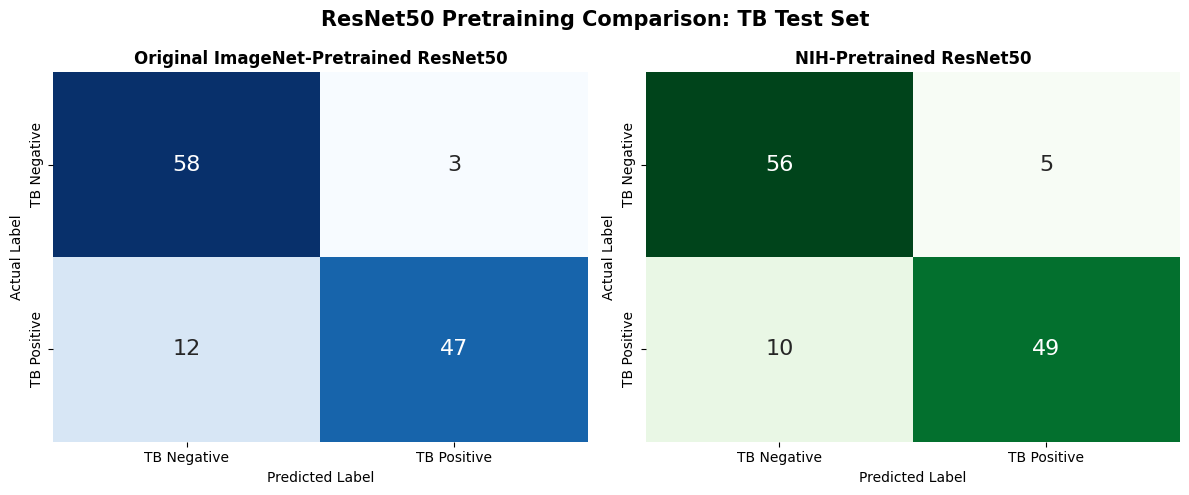

Confusion matrix comparison saved to: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/NIH_Domain_Pretraining/resnet50_confusion_matrix_comparison.png

SUCCESS: Confusion matrix visualisation created!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

RESULTS_DIR = (
    Path("/content/drive/MyDrive/Insight_Hunters_Project")
    / "04_Results"
    / "NIH_Domain_Pretraining"
)

# Original ResNet50 confusion matrix
# TN = 58, FP = 3, FN = 12, TP = 47
original_cm = np.array([
    [58, 3],
    [12, 47]
])

# Loading the NIH-pretrained ResNet50 confusion matrix
nih_metrics = pd.read_csv(
    RESULTS_DIR / "nih_tb_final_test_metrics.csv"
).iloc[0]

nih_cm = np.array([
    [int(nih_metrics["TN"]), int(nih_metrics["FP"])],
    [int(nih_metrics["FN"]), int(nih_metrics["TP"])]
])

# Creating a side-by-side visualisation
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

class_labels = ["TB Negative", "TB Positive"]

sns.heatmap(
    original_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels,
    cbar=False,
    ax=axes[0],
    annot_kws={"size": 16}
)

axes[0].set_title(
    "Original ImageNet-Pretrained ResNet50",
    fontsize=12,
    fontweight="bold"
)

axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    nih_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_labels,
    yticklabels=class_labels,
    cbar=False,
    ax=axes[1],
    annot_kws={"size": 16}
)

axes[1].set_title(
    "NIH-Pretrained ResNet50",
    fontsize=12,
    fontweight="bold"
)

axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.suptitle(
    "ResNet50 Pretraining Comparison: TB Test Set",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

# Saving the high-resolution figure
figure_path = RESULTS_DIR / "resnet50_confusion_matrix_comparison.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix comparison saved to:", figure_path)
print("\nSUCCESS: Confusion matrix visualisation created!")